# Fig. 2: benchmark on paired mouse-brain simulations with planted ground truth

Five coronal sections (A8, A9, B17, B3, B5) each paired with a copy carrying three planted salient domains
(composition shifts) in the disease arm. Readout identical for every method: 3-hop CellCharter aggregation of the saved
embedding, raw KMeans with k = number of planted classes. Means over 5 sections (background / salient ARI):
Haruka 0.540 / 0.854; CINEMA-OT + CC 0.510 / 0.816; expression + aggregation 0.339 / 0.815; scVI + CC 0.479 / 0.139;
ContrastiveVI + CC 0.474 / 0.022. With n = 5 no test can reach p < 0.0625, so section win counts are shown.
Note: the mouse-brain fits used a **Poisson** likelihood and batch = timepoint injected everywhere (pre-dates the
decoder-only batch default); `--gene_likelihood poisson` must now be passed explicitly.

In [1]:
import sys, pathlib; sys.path.insert(0, str(next(p for p in [pathlib.Path.cwd(), pathlib.Path.cwd() / 'notebooks'] if (p / 'repro.py').exists())))
from repro import run, require, show, fetch, STAGES, H, WK, PY, PY_VIO, GPU
# Default: end to end (download from Hugging Face -> fit -> analyses -> figure; hours on one GPU).
# Redraw only from saved outputs: STAGES.update(download=False, fit=False, analysis=False)  (or env HARUKA_FIGURE_ONLY=1)
# Rebuild the inputs from the raw public releases instead of Hugging Face: STAGES.update(data=True)
print(H, STAGES)

/home/yancui/haruka_v2 {'download': True, 'data': False, 'fit': False, 'analysis': False, 'figure': True}


## 0 Preprocessed data (Hugging Face)

The ready-to-fit inputs are read directly from [C1vy/haruka_v2_data](https://huggingface.co/datasets/C1vy/haruka_v2_data) (cached in `hf_data/`) and linked to the paths the scripts read. The data stage below rebuilds the same files from the raw releases and is off by default.

In [2]:
fetch('02_fig2_benchmark/mouse_brain_A8_paired.h5ad', H / 'bench_mouse_brain_scviva/data_composition_pairs_all/mouse_brain_A8_paired.h5ad')
fetch('02_fig2_benchmark/mouse_brain_A9_paired.h5ad', H / 'bench_mouse_brain_scviva/data_composition_pairs_all/mouse_brain_A9_paired.h5ad')
fetch('02_fig2_benchmark/mouse_brain_B17_paired.h5ad', H / 'bench_mouse_brain_scviva/data_composition_pairs_all/mouse_brain_B17_paired.h5ad')
fetch('02_fig2_benchmark/mouse_brain_B3_paired.h5ad', H / 'bench_mouse_brain_scviva/data_composition_pairs_all/mouse_brain_B3_paired.h5ad')
fetch('02_fig2_benchmark/mouse_brain_B5_paired.h5ad', H / 'bench_mouse_brain_scviva/data_composition_pairs_all/mouse_brain_B5_paired.h5ad')

[download] 02_fig2_benchmark/mouse_brain_A8_paired.h5ad: /home/yancui/haruka_v2/bench_mouse_brain_scviva/data_composition_pairs_all/mouse_brain_A8_paired.h5ad already present, kept


/home/yancui/.conda/envs/haruka2/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[download] 02_fig2_benchmark/mouse_brain_A9_paired.h5ad: /home/yancui/haruka_v2/bench_mouse_brain_scviva/data_composition_pairs_all/mouse_brain_A9_paired.h5ad already present, kept
[download] 02_fig2_benchmark/mouse_brain_B17_paired.h5ad: /home/yancui/haruka_v2/bench_mouse_brain_scviva/data_composition_pairs_all/mouse_brain_B17_paired.h5ad already present, kept
[download] 02_fig2_benchmark/mouse_brain_B3_paired.h5ad: /home/yancui/haruka_v2/bench_mouse_brain_scviva/data_composition_pairs_all/mouse_brain_B3_paired.h5ad already present, kept
[download] 02_fig2_benchmark/mouse_brain_B5_paired.h5ad: /home/yancui/haruka_v2/bench_mouse_brain_scviva/data_composition_pairs_all/mouse_brain_B5_paired.h5ad already present, kept


PosixPath('/home/yancui/haruka_v2/bench_mouse_brain_scviva/data_composition_pairs_all/mouse_brain_B5_paired.h5ad')

## 1 Simulated paired sections

In [3]:
B = H / 'bench_mouse_brain_scviva'; SECTIONS = ['A8', 'A9', 'B17', 'B3', 'B5']
run(f'{PY} build_paired_sections.py --source /home/yancui/virtualorganoid/notebook/aging_coronal_spatial_mouse.h5ad --out_dir data_composition_pairs_all --seed 20260815 --n_domains 3 --shift_fraction 0.5 --sections ' + ' '.join(SECTIONS), 'data', cwd=B)

[skip: data stage off] /home/yancui/.conda/envs/haruka2/bin/python build_paired_sections.py --source /home/yancui/virtualorganoid/notebook/aging_coronal_spatial_mouse.h5ad --out_dir data_composition_pairs_all --seed 20260815 --n_domains 3 --shift_fraction 0.5 --sections A8 A9 B17 B3 B5


## 2 Haruka fits: default λ = 10 (shown) and the λ = 25 gated / independent ablations (~3 min per section)

In [4]:
COMMON = ('--seed 0 --max_epochs 150 --batch_size 2048 --n_latent 32 --n_hidden 256 --n_layers 1 --decoder_layers 2 --k_niche 20 '
          '--neighbor_embedding_dim 16 --composition_loss_weight 1 --neighbor_mean_loss_weight 1 --spatial_weight 100 --direct_only '
          '--batch_key timepoint --sample_key slice_id --condition_key condition --target_label disease --cell_type_key observed_celltype '
          '--num_workers 4 --gene_likelihood poisson')
RUNS = {'results_shared_full_niche_compgated_lambda10': ('composition_gated', 10, 'haruka_shared_full_niche_compgated_seed0'),
        'results_shared_full_niche_compgated_lambda25': ('composition_gated', 25, 'haruka_shared_full_niche_compgated_seed0'),
        'results_shared_full_niche_lambda25': ('independent', 25, 'haruka_shared_full_niche_seed0')}
for root, (mode, lam, run_dir) in RUNS.items():
    for s in SECTIONS:
        d = f'data_composition_pairs_all/mouse_brain_{s}_paired.h5ad'
        run(f'{PY} run_haruka_shared_decoder.py --data {d} --out_root {root} --neighbor_expression_mode {mode} --zs_independence_penalty {lam} {COMMON}', 'fit', cwd=B)
        run(f'{PY} aggregate_haruka_latent_cellcharter.py --data {d} --input_dir {root}/mouse_brain_{s}_paired/{run_dir} --output_dir {root}_cc/mouse_brain_{s}_paired/haruka_z_s_cellcharter_seed0', 'analysis', cwd=B)
        run(f'{PY} score_pair_direct_kmeans.py --data {d} --emb_dir {root}_cc/mouse_brain_{s}_paired/haruka_z_s_cellcharter_seed0', 'analysis', cwd=B)
run(f'{PY} summarize_composition_gated_lambda_sweep.py --base . --lambdas 10 25 --sections ' + ' '.join(SECTIONS) + ' --seed 0 --max_cv_cells 10000 --out_dir results_shared_full_niche_compgated_lambda_sweep', 'analysis', cwd=B)

[skip: fit stage off] /home/yancui/.conda/envs/haruka2/bin/python run_haruka_shared_decoder.py --data data_composition_pairs_all/mouse_brain_A8_paired.h5ad --out_root results_shared_full_niche_compgated_lambda10 --neighbor_expression_mode composition_gated --zs_independence_penalty 10 --seed 0 --max_epochs 150 --batch_size 2048 --n_latent 32 --n_hidden 256 --n_layers 1 --decoder_layers 2 --k_niche 20 --neighbor_embedding_dim 16 --composition_loss_weight 1 --neighbor_mean_loss_weight 1 --spatial_weight 100 --direct_only --batch_key timepoint --sample_key slice_id --condition_key condition --target_label disease --cell_type_key observed_celltype --num_workers 4 --gene_likelihood poisson
[skip: analysis stage off] /home/yancui/.conda/envs/haruka2/bin/python aggregate_haruka_latent_cellcharter.py --data data_composition_pairs_all/mouse_brain_A8_paired.h5ad --input_dir results_shared_full_niche_compgated_lambda10/mouse_brain_A8_paired/haruka_shared_full_niche_compgated_seed0 --output_dir re

## 3 Baselines: scVI / ContrastiveVI / expression + CellCharter, CINEMA-OT (env `vio`)

In [5]:
for s in SECTIONS:
    d = f'data_composition_pairs_all/mouse_brain_{s}_paired.h5ad'; root = 'results_direct_kmeans' if s == 'A8' else 'results_cross_section'
    run(f'{PY} {H}/bench_merfish/run_baselines_2x2.py --data {d} --methods pca cellcharter contrastivevi --out_root {root}/baselines --seed 0 --max_epochs 150 --batch_size 2048', 'fit', cwd=B)
    cine = f'{root}/cinema_minibatch/mouse_brain_{s}_paired/cinemaot_minibatch_b2048_e3_seed0'
    run(f'{PY_VIO} {H}/bench_merfish/run_cinemaot_minibatch.py --data {d} --out_root {root}/cinema_minibatch --seed 0 --dim 20 --thres 0.15 --transport_batch_size 2048 --n_ensembles 3', 'fit', cwd=B)
    run(f'{PY} {H}/bench_merfish/cc_add_spatial.py --data {d} --result_dir {cine}', 'analysis', cwd=B)
    run(f'{PY} score_composition_controls.py --data {d} --out {root}/composition_controls_{s}.json --k_niche 20 --seed 0 --n_init 20', 'analysis', cwd=B)
    run(f'for e in {root}/baselines/mouse_brain_{s}_paired/*/ {cine}; do {PY} score_pair_direct_kmeans.py --data {d} --emb_dir $e; done', 'analysis', cwd=B)
# per-section haruka/cinema result jsons are listed in results_cross_section/summary/per_section_metrics.csv (result_json)
run(f'{PY} summarize_all_cross_section_methods.py', 'analysis', cwd=B)
run(f'{PY} build_lambda25_comparison.py', 'analysis', cwd=B)

[skip: fit stage off] /home/yancui/.conda/envs/haruka2/bin/python /home/yancui/haruka_v2/bench_merfish/run_baselines_2x2.py --data data_composition_pairs_all/mouse_brain_A8_paired.h5ad --methods pca cellcharter contrastivevi --out_root results_direct_kmeans/baselines --seed 0 --max_epochs 150 --batch_size 2048
[skip: fit stage off] /home/yancui/.conda/envs/vio/bin/python /home/yancui/haruka_v2/bench_merfish/run_cinemaot_minibatch.py --data data_composition_pairs_all/mouse_brain_A8_paired.h5ad --out_root results_direct_kmeans/cinema_minibatch --seed 0 --dim 20 --thres 0.15 --transport_batch_size 2048 --n_ensembles 3
[skip: analysis stage off] /home/yancui/.conda/envs/haruka2/bin/python /home/yancui/haruka_v2/bench_merfish/cc_add_spatial.py --data data_composition_pairs_all/mouse_brain_A8_paired.h5ad --result_dir results_direct_kmeans/cinema_minibatch/mouse_brain_A8_paired/cinemaot_minibatch_b2048_e3_seed0
[skip: analysis stage off] /home/yancui/.conda/envs/haruka2/bin/python score_compo

## 4 Figure: per-section table, B5 maps cache (recomputed only if missing), panels

In [6]:
run(f'{PY} figures_paper/fig2_benchmark_stats.py', 'figure')
run(f'{PY} figures_paper/fig2_benchmark_maps.py --section B5', 'figure')
run(f'{PY} figures_paper/fig2/make_fig2.py', 'figure')
import pandas as pd
d = pd.read_csv(H / 'figures_paper/fig2_benchmark_per_section.csv'); d.groupby('method')[['bg', 'sal', 'balanced']].mean().round(3).sort_values('balanced', ascending=False)

wrote /home/yancui/haruka_v2/figures_paper/fig2_benchmark_stats.png
                                          bg           sal        balanced       
                                        mean    std   mean    std     mean    std
method                                                                           
Haruka λ=10 composition-gated          0.540  0.046  0.854  0.124    0.697  0.060
Haruka λ=25 composition-gated          0.523  0.043  0.849  0.125    0.686  0.058
Haruka λ=25 independent                0.549  0.081  0.848  0.124    0.699  0.046
Mini-batch CINEMA-OT + CellCharter     0.510  0.041  0.816  0.052    0.663  0.043
Expression + neighborhood aggregation  0.339  0.089  0.815  0.052    0.577  0.032
scVI + CellCharter                     0.479  0.018  0.139  0.171    0.309  0.077
ContrastiveVI z/s + CellCharter        0.474  0.028  0.022  0.023    0.248  0.024
[figure] exit 0 in 2s: /home/yancui/.conda/envs/haruka2/bin/python figures_paper/fig2_benchmark_stats.py


loaded cache
wrote /home/yancui/haruka_v2/figures_paper/fig2_benchmark_maps_B5.png
[figure] exit 0 in 20s: /home/yancui/.conda/envs/haruka2/bin/python figures_paper/fig2_benchmark_maps.py --section B5


fig2a_ground_truth.svg           fonts [6.0, 6.5]  OK
fig2b_default.svg                fonts [6.0, 6.5]  OK
fig2b_cinema.svg                 fonts [6.0, 6.5]  OK
fig2b_expr.svg                   fonts [6.0, 6.5]  OK
fig2b_scvi.svg                   fonts [6.0, 6.5]  OK
fig2b_cvi.svg                    fonts [6.0, 6.5]  OK
fig2c_background_ari.svg         fonts [6.0, 6.5]  OK
fig2d_salient_ari.svg            fonts [6.0, 6.5]  OK
fig2e_paired_difference.svg      fonts [5.6, 6.0, 6.5]  OK
fig2_composite.svg               fonts [5.6, 6.0, 6.5, 8.0]  OK

ALL SVGs >= 5.5 pt
[figure] exit 0 in 33s: /home/yancui/.conda/envs/haruka2/bin/python figures_paper/fig2/make_fig2.py


,bg,sal,balanced
method,,,
Haruka λ=25 independent,0.549,0.848,0.699
Haruka λ=10 composition-gated,0.540,0.854,0.697
Haruka λ=25 composition-gated,0.523,0.849,0.686
Mini-batch CINEMA-OT + CellCharter,0.510,0.816,0.663
Expression + neighborhood aggregation,0.339,0.815,0.577
scVI + CellCharter,0.479,0.139,0.309
ContrastiveVI z/s + CellCharter,0.474,0.022,0.248


## Figure

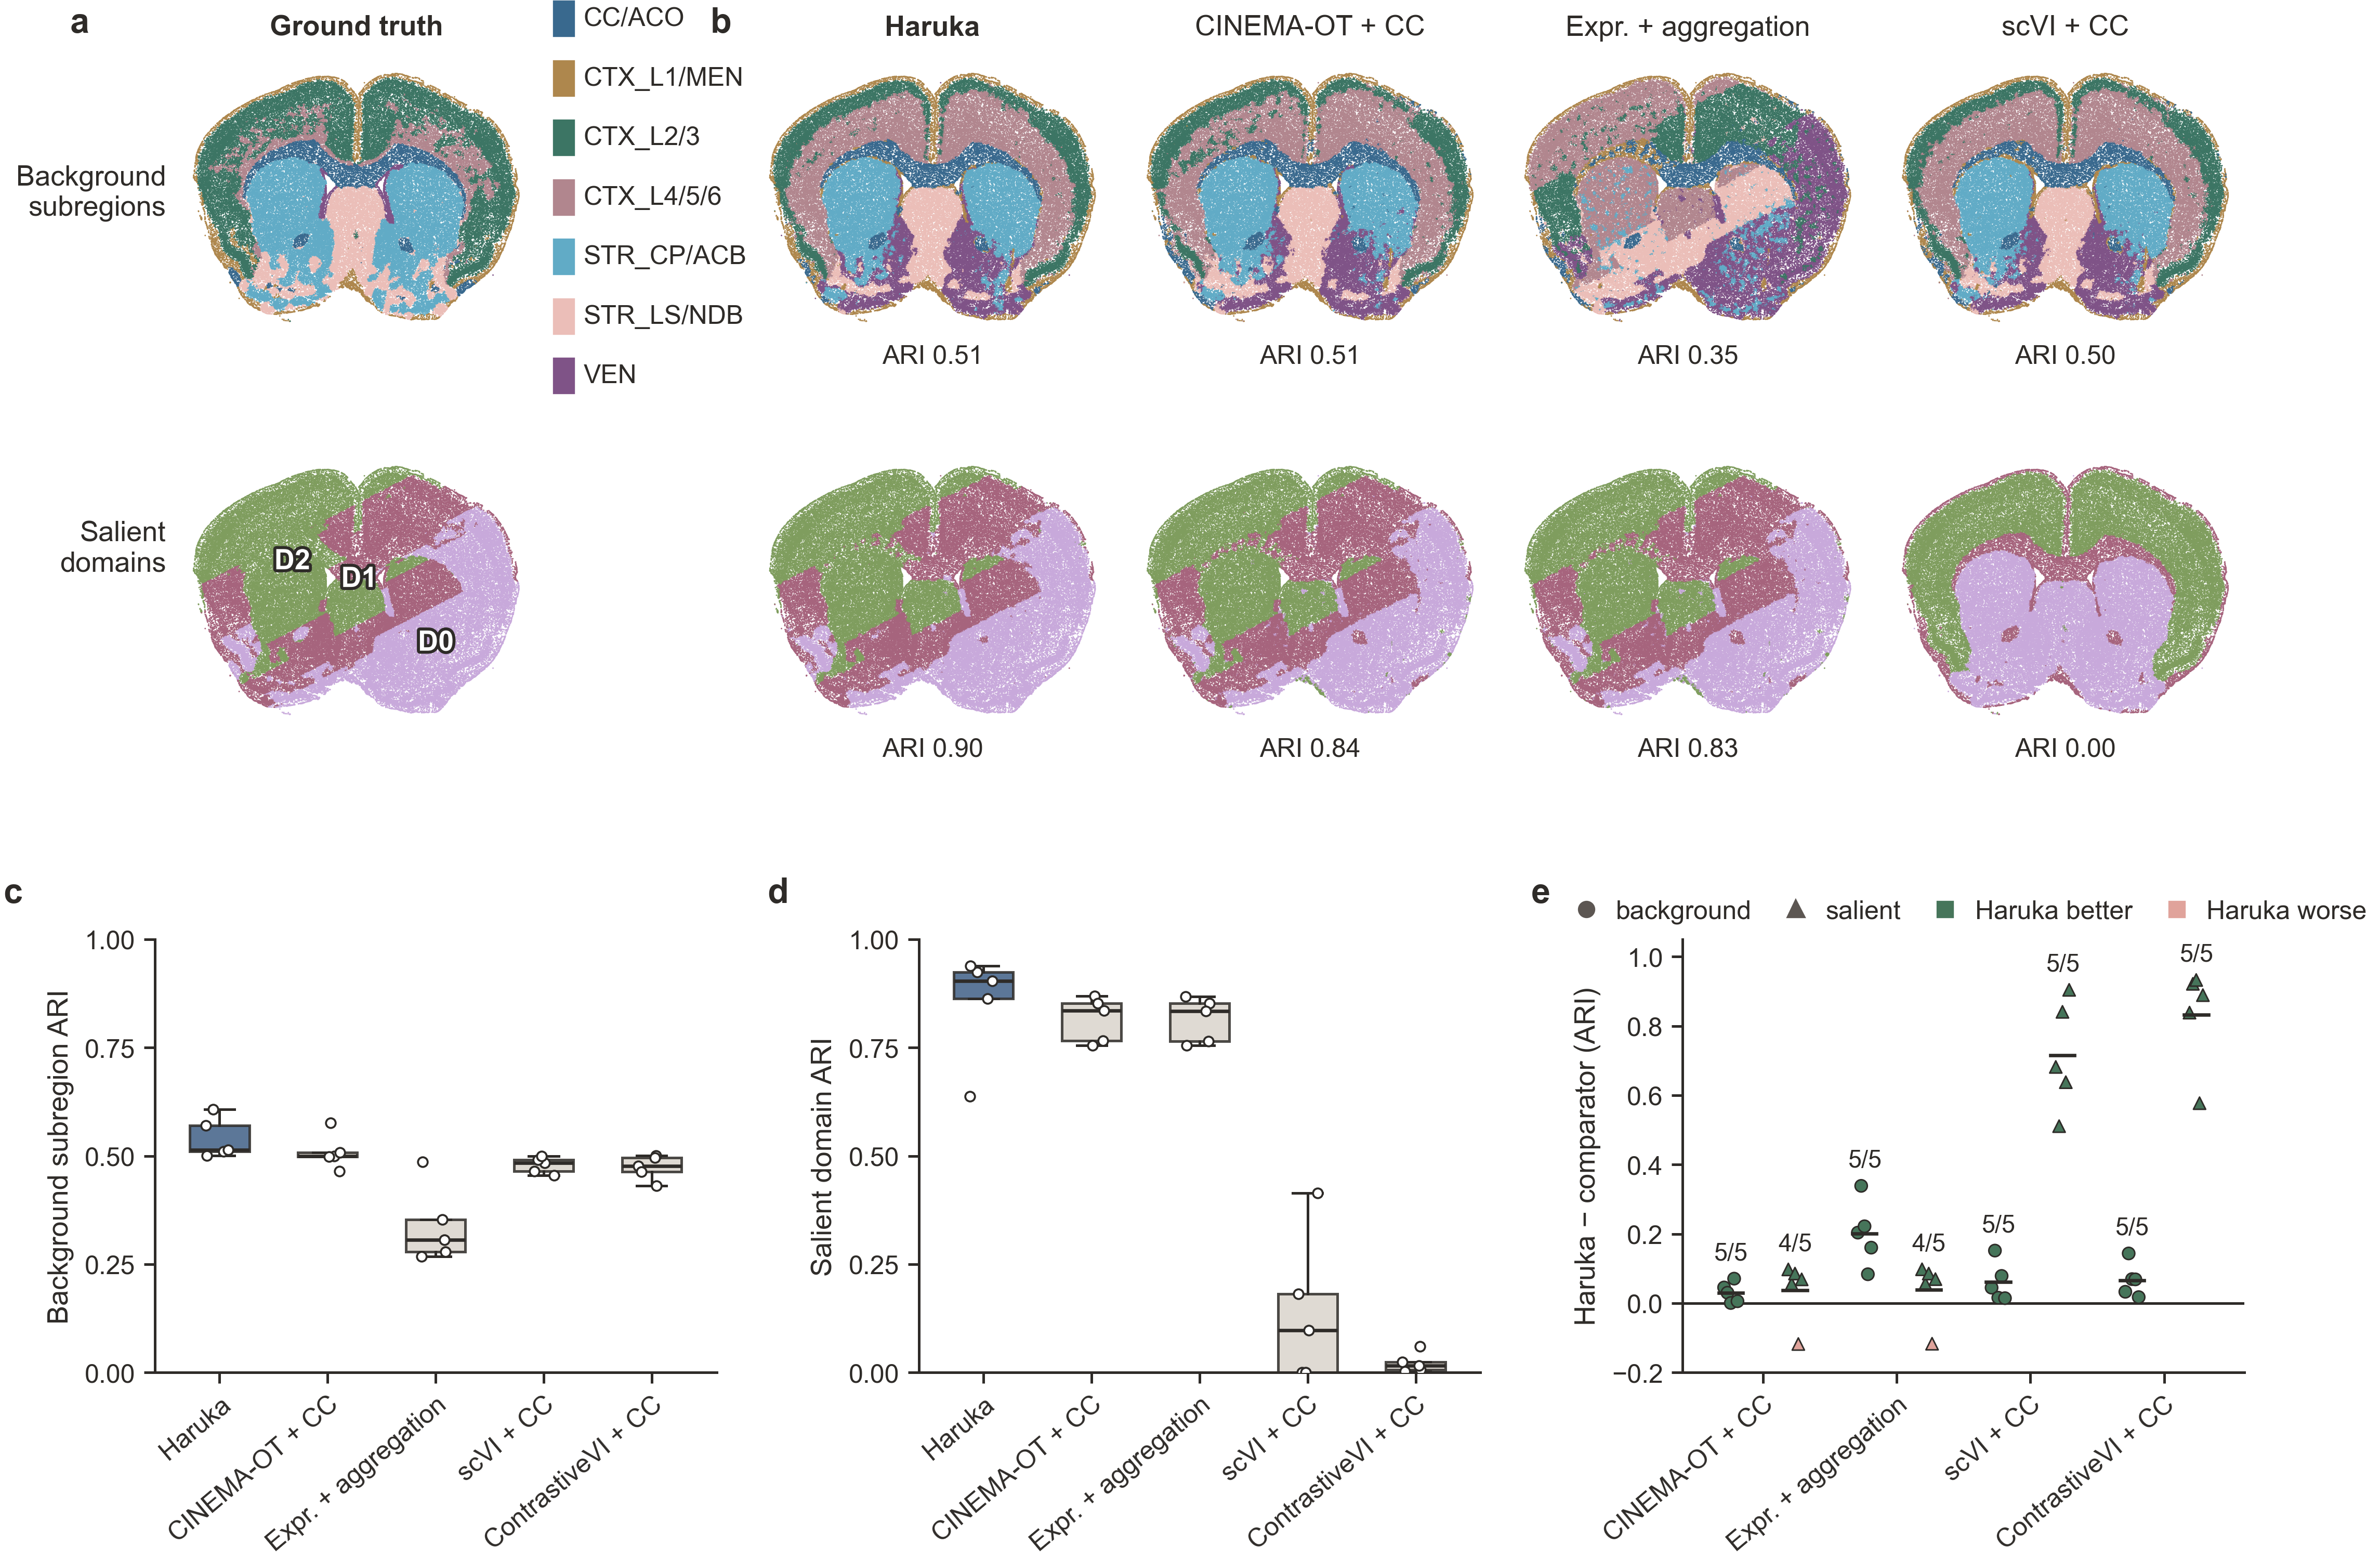

In [7]:
show(H / 'figures_paper/fig2/fig2_composite.png')